In [0]:
%sql

SELECT
    dp.product_category_name_english AS categoria,
    ROUND(SUM(fs.price), 2) AS receita_total,
    COUNT(DISTINCT fs.order_id) AS quantidade_pedidos,
    COUNT(*) AS quantidade_itens
FROM olist_dw.dw.fact_sales fs
INNER JOIN olist_dw.dw.dim_product dp
    ON fs.product_sk = dp.product_sk
WHERE dp.product_category_name_english IS NOT NULL
GROUP BY
    dp.product_category_name_english
ORDER BY
    receita_total DESC
LIMIT 10;


categoria,receita_total,quantidade_pedidos,quantidade_itens
health_beauty,1258681.34,8836,9670
watches_gifts,1205005.68,5624,5991
bed_bath_table,1036988.68,9417,11115
sports_leisure,988048.97,7720,8641
computers_accessories,911954.32,6689,7827
furniture_decor,729762.49,6449,8334
cool_stuff,635290.85,3632,3796
housewares,632248.66,5884,6964
auto,592720.11,3897,4235
garden_tools,485256.46,3518,4347


In [0]:
%sql

SELECT
    DATE_TRUNC('MONTH', order_purchase_timestamp) AS mes,
    ROUND(SUM(price), 2) AS receita_total,
    COUNT(DISTINCT order_id) AS quantidade_pedidos
FROM olist_dw.dw.fact_sales
GROUP BY
    DATE_TRUNC('MONTH', order_purchase_timestamp)
ORDER BY
    mes;


mes,receita_total,quantidade_pedidos
2016-09-01T00:00:00.000Z,267.36,3
2016-10-01T00:00:00.000Z,49507.66,308
2016-12-01T00:00:00.000Z,10.9,1
2017-01-01T00:00:00.000Z,119739.0,786
2017-02-01T00:00:00.000Z,244382.02,1724
2017-03-01T00:00:00.000Z,373933.01,2640
2017-04-01T00:00:00.000Z,362500.78,2390
2017-05-01T00:00:00.000Z,503426.89,3648
2017-06-01T00:00:00.000Z,436478.64,3237
2017-07-01T00:00:00.000Z,496024.17,3950


In [0]:
%sql

SELECT
    DATE_TRUNC('MONTH', o.order_purchase_timestamp) AS mes,
    COUNT(DISTINCT o.order_id) AS pedidos_na_orders,
    COUNT(DISTINCT fs.order_id) AS pedidos_na_fact_sales,
    COUNT(fs.order_id) AS itens_na_fact_sales,
    ROUND(SUM(fs.price), 2) AS receita_produtos
FROM olist_dw.dw.orders o
LEFT JOIN olist_dw.dw.fact_sales fs
    ON o.order_id = fs.order_id
GROUP BY DATE_TRUNC('MONTH', o.order_purchase_timestamp)
ORDER BY mes;


mes,pedidos_na_orders,pedidos_na_fact_sales,itens_na_fact_sales,receita_produtos
2016-09-01T00:00:00.000Z,4,3,6,267.36
2016-10-01T00:00:00.000Z,324,308,363,49507.66
2016-12-01T00:00:00.000Z,1,1,1,10.9
2017-01-01T00:00:00.000Z,797,786,951,119739.0
2017-02-01T00:00:00.000Z,1771,1724,1939,244382.02
2017-03-01T00:00:00.000Z,2681,2640,3003,373933.01
2017-04-01T00:00:00.000Z,2403,2390,2683,362500.78
2017-05-01T00:00:00.000Z,3688,3648,4119,503426.89
2017-06-01T00:00:00.000Z,3265,3237,3607,436478.64
2017-07-01T00:00:00.000Z,4007,3950,4496,496024.17


In [0]:
%sql

SELECT
    DATE_TRUNC('MONTH', order_purchase_timestamp) AS mes,
    COUNT(*) AS total_pedidos,
    MIN(order_purchase_timestamp) AS primeira_compra,
    MAX(order_purchase_timestamp) AS ultima_compra
FROM olist_dw.dw.orders
GROUP BY DATE_TRUNC('MONTH', order_purchase_timestamp)
ORDER BY mes;


mes,total_pedidos,primeira_compra,ultima_compra
2016-09-01T00:00:00.000Z,4,2016-09-05T00:15:19.000Z,2016-09-15T15:16:38.000Z
2016-10-01T00:00:00.000Z,324,2016-10-03T01:07:52.000Z,2016-10-22T10:25:27.000Z
2016-12-01T00:00:00.000Z,1,2016-12-24T01:16:47.000Z,2016-12-24T01:16:47.000Z
2017-01-01T00:00:00.000Z,797,2017-01-05T13:56:06.000Z,2017-01-31T23:57:33.000Z
2017-02-01T00:00:00.000Z,1771,2017-02-01T00:31:13.000Z,2017-02-28T23:57:21.000Z
2017-03-01T00:00:00.000Z,2681,2017-03-01T00:01:33.000Z,2017-03-31T23:58:07.000Z
2017-04-01T00:00:00.000Z,2403,2017-04-01T00:10:02.000Z,2017-04-30T23:33:21.000Z
2017-05-01T00:00:00.000Z,3688,2017-05-01T00:04:52.000Z,2017-05-31T23:59:25.000Z
2017-06-01T00:00:00.000Z,3265,2017-06-01T00:12:24.000Z,2017-06-30T23:54:21.000Z
2017-07-01T00:00:00.000Z,4007,2017-07-01T00:15:32.000Z,2017-07-31T23:54:58.000Z


In [0]:
%sql

SELECT
    DATE_TRUNC('MONTH', order_purchase_timestamp) AS mes,
    ROUND(SUM(price), 2) AS receita_total,
    COUNT(DISTINCT order_id) AS quantidade_pedidos
FROM olist_dw.dw.fact_sales
WHERE order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp < '2018-09-01'
GROUP BY DATE_TRUNC('MONTH', order_purchase_timestamp)
ORDER BY mes;


mes,receita_total,quantidade_pedidos
2017-01-01T00:00:00.000Z,119739.0,786
2017-02-01T00:00:00.000Z,244382.02,1724
2017-03-01T00:00:00.000Z,373933.01,2640
2017-04-01T00:00:00.000Z,362500.78,2390
2017-05-01T00:00:00.000Z,503426.89,3648
2017-06-01T00:00:00.000Z,436478.64,3237
2017-07-01T00:00:00.000Z,496024.17,3950
2017-08-01T00:00:00.000Z,574140.23,4301
2017-09-01T00:00:00.000Z,624014.85,4244
2017-10-01T00:00:00.000Z,665236.29,4569


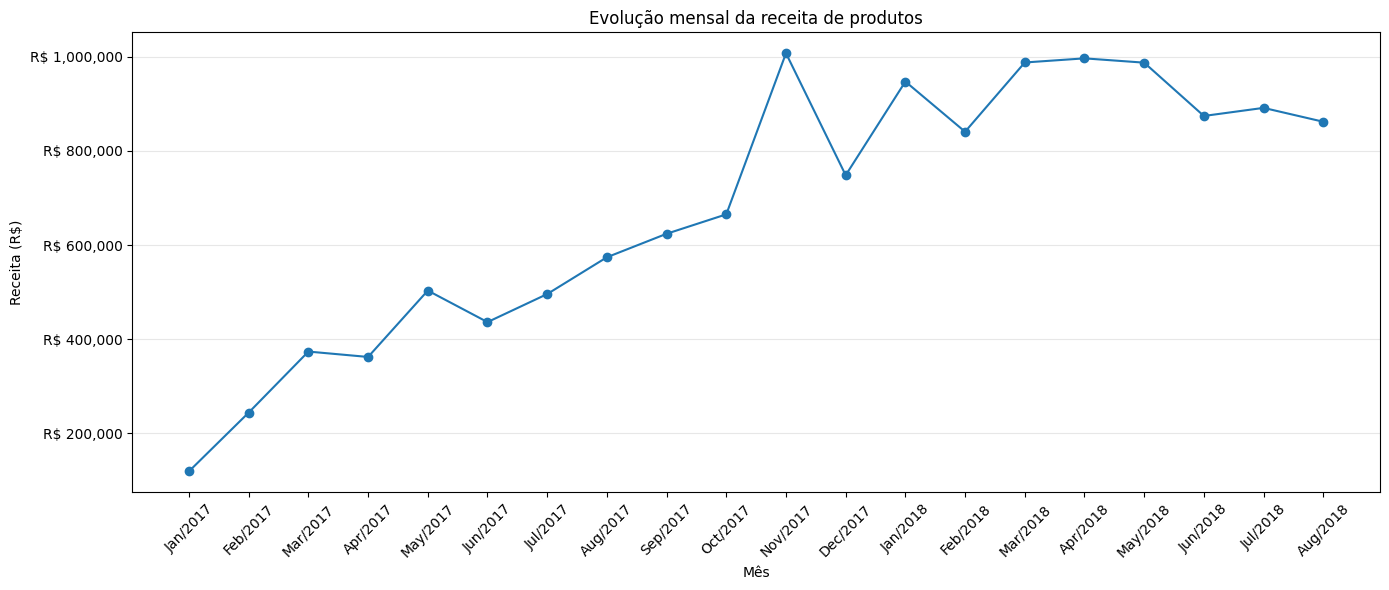

In [0]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Consulta dos dados mensais
df_monthly = spark.sql("""
    SELECT
        DATE_TRUNC('MONTH', order_purchase_timestamp) AS mes,
        SUM(price) AS receita_total
    FROM olist_dw.dw.fact_sales
    WHERE order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp < '2018-09-01'
    GROUP BY DATE_TRUNC('MONTH', order_purchase_timestamp)
    ORDER BY mes
""").toPandas()

# Preparação dos dados
df_monthly["mes"] = df_monthly["mes"].dt.strftime("%b/%Y")

# Criação do gráfico
plt.figure(figsize=(14, 6))
plt.plot(
    df_monthly["mes"],
    df_monthly["receita_total"],
    marker="o"
)

plt.title("Evolução mensal da receita de produtos")
plt.xlabel("Mês")
plt.ylabel("Receita (R$)")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("R$ {x:,.0f}")
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Exportação
plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/receita_mensal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


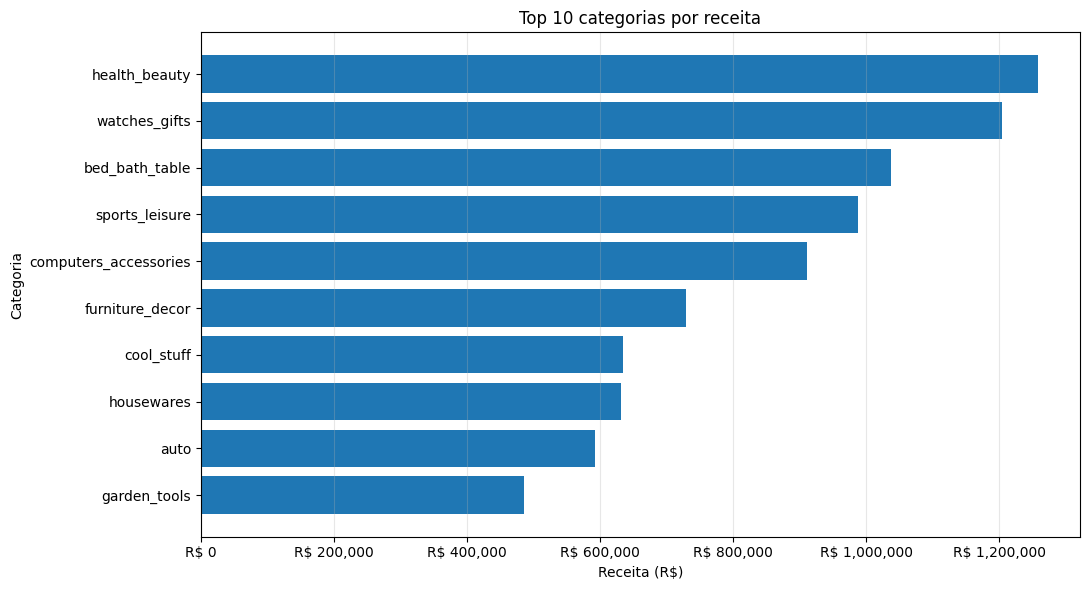

In [0]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

df_categories = spark.sql("""
    SELECT
        dp.product_category_name_english AS categoria,
        SUM(fs.price) AS receita_total
    FROM olist_dw.dw.fact_sales fs
    INNER JOIN olist_dw.dw.dim_product dp
        ON fs.product_sk = dp.product_sk
    WHERE dp.product_category_name_english IS NOT NULL
    GROUP BY dp.product_category_name_english
    ORDER BY receita_total DESC
    LIMIT 10
""").toPandas()

df_categories = df_categories.sort_values("receita_total")

plt.figure(figsize=(11, 6))
plt.barh(
    df_categories["categoria"],
    df_categories["receita_total"]
)

plt.title("Top 10 categorias por receita")
plt.xlabel("Receita (R$)")
plt.ylabel("Categoria")
plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("R$ {x:,.0f}")
)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/top_10_categorias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
